In [ ]:
приклад1

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import matplotlib.pyplot as plt
import numpy as np
import os
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from torchvision.datasets import ImageFolder

In [10]:
def visualize_images(dataloader, class_names=None, num_images=5):
    images, labels = next(iter(dataloader))
    plt.figure(figsize=(15, 3))
    for i in range(num_images):
        img = images[i].numpy().transpose((1, 2, 0))
        img = np.clip(img * 0.5 + 0.5, 0, 1)
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        if class_names:
            plt.title(f'Class: {class_names[labels[i]]}')
        else:
            plt.title(f'Label: {labels[i].item()}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def visualize_predictions(model, dataloader, device, class_names=None, num_images=5):
    model.eval()
    images, labels = next(iter(dataloader))
    with torch.no_grad():
        outputs = model(images.to(device))
        _, predicted = torch.max(outputs, 1)

    plt.figure(figsize=(15, 3))
    for i in range(num_images):
        img = images[i].numpy().transpose((1, 2, 0))
        img = np.clip(img * 0.5 + 0.5, 0, 1)
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        if class_names:
            true_label = class_names[labels[i]]
            pred_label = class_names[predicted[i]]
            color = 'green' if labels[i] == predicted[i] else 'red'
            plt.title(f'True: {true_label}\nPred: {pred_label}', color=color)
        else:
            color = 'green' if labels[i] == predicted[i] else 'red'
            plt.title(f'True: {labels[i]}\nPred: {predicted[i]}', color=color)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

In [11]:
class CNN(nn.Module):
    def __init__(self, num_classes):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.fc1 = nn.Linear(64 * 56 * 56, 128)
        self.fc2 = nn.Linear(128, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x))
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [12]:
def train_model(model, train_loader, criterion, optimizer, device, epochs=5):
    model.train()
    train_losses = []
    train_accs = []

    for epoch in range(epochs):
        total_loss = 0
        correct = 0
        total = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        epoch_loss = total_loss/len(train_loader)
        epoch_acc = correct/total
        train_losses.append(epoch_loss)
        train_accs.append(epoch_acc)
        print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}")

    return train_losses, train_accs

def evaluate_model(model, test_loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    accuracy = correct / total
    print(f'Test Accuracy: {accuracy:.4f}')
    return accuracy

Sample training images:


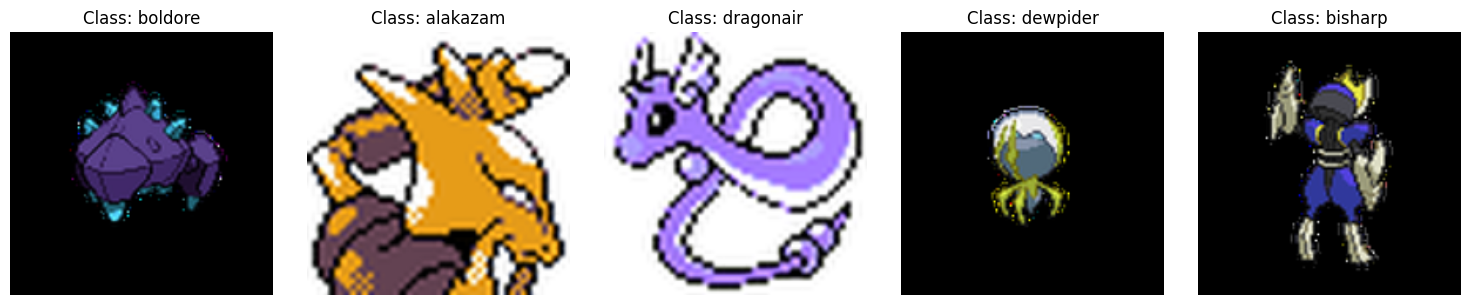


Training model...
Epoch 1/5, Loss: 5.5097, Accuracy: 0.0132
Epoch 2/5, Loss: 3.7344, Accuracy: 0.2754
Epoch 3/5, Loss: 1.1124, Accuracy: 0.7602
Epoch 4/5, Loss: 0.2242, Accuracy: 0.9487
Epoch 5/5, Loss: 0.0523, Accuracy: 0.9892

Evaluating model...
Test Accuracy: 0.7931

Model predictions on test set:


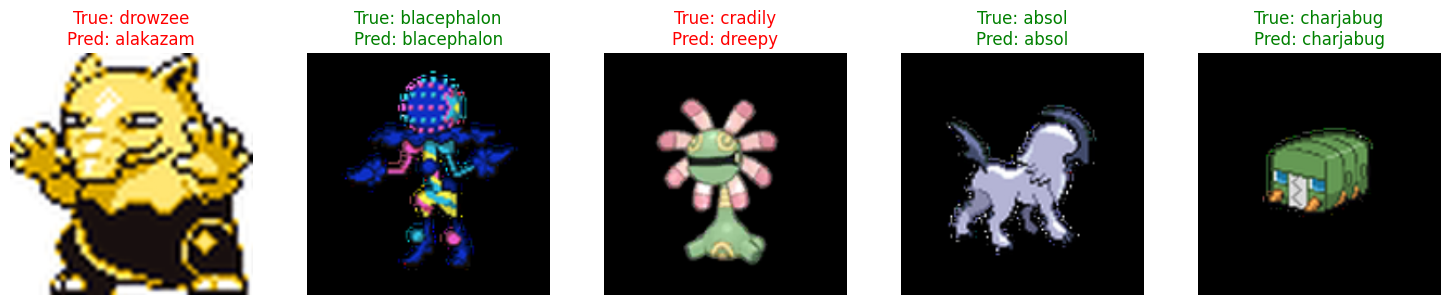

Model (loaded from checkpoint) predictions:


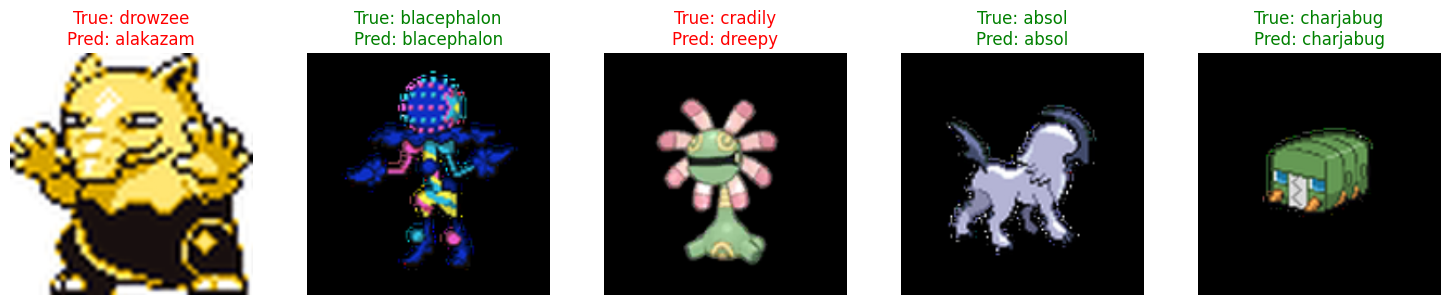

In [13]:
def main():
    # Set device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Define transforms
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    # Load dataset
    data_dir = "./variant-1/variant-1" # Provide your dataset directory
    train_dir = os.path.join(data_dir, "train")
    test_dir = os.path.join(data_dir, "test")

    if os.path.exists(train_dir) and os.path.exists(test_dir):
        train_dataset = ImageFolder(root=train_dir, transform=transform)
        test_dataset = ImageFolder(root=test_dir, transform=transform)
        class_names = train_dataset.classes
    else:
        dataset = ImageFolder(root=data_dir, transform=transform)
        class_names = dataset.classes
        indices = list(range(len(dataset)))
        train_indices, test_indices = train_test_split(indices, test_size=0.2, random_state=42)
        train_dataset = Subset(dataset, train_indices)
        test_dataset = Subset(dataset, test_indices)

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    # Visualize training images
    print("Sample training images:")
    visualize_images(train_loader, class_names)

    # Initialize model
    num_classes = len(class_names)
    model = CNN(num_classes=num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Train model
    print("\nTraining model...")
    train_losses, train_accs = train_model(model, train_loader, criterion, optimizer, device, epochs=5)

    # Evaluate model
    print("\nEvaluating model...")
    test_accuracy = evaluate_model(model, test_loader, device)

    # Visualize predictions
    print("\nModel predictions on test set:")
    visualize_predictions(model, test_loader, device, class_names)

    # Save model
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_losses': train_losses,
        'train_accs': train_accs,
        'test_accuracy': test_accuracy,
        'class_names': class_names
    }, "model_checkpoint.pth")

    # Check that model is loaded correctly after saving
    load_and_visualize("model_checkpoint.pth", test_loader, device)

def load_and_visualize(checkpoint_path, test_loader, device):
    # Load checkpoint
    checkpoint = torch.load(checkpoint_path)
    num_classes = len(checkpoint['class_names'])

    # Initialize and load model
    model = CNN(num_classes=num_classes)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval()

    # Visualize predictions
    print("Model (loaded from checkpoint) predictions:")
    visualize_predictions(model, test_loader, device, checkpoint['class_names'])

    return model

if __name__ == '__main__':
    main()

In [ ]:
приклад 2

Using device: cpu


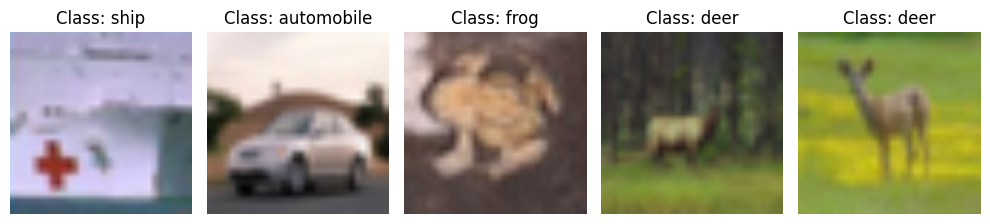

Training started...
Epoch [1/5], Step [100/1563], Loss: 1.3013
Epoch [1/5], Step [200/1563], Loss: 0.9079
Epoch [1/5], Step [300/1563], Loss: 0.8063
Epoch [1/5], Step [400/1563], Loss: 0.7277
Epoch [1/5], Step [500/1563], Loss: 0.7096
Epoch [1/5], Step [600/1563], Loss: 0.6559
Epoch [1/5], Step [700/1563], Loss: 0.6631
Epoch [1/5], Step [800/1563], Loss: 0.6037
Epoch [1/5], Step [900/1563], Loss: 0.5870
Epoch [1/5], Step [1000/1563], Loss: 0.6064
Epoch [1/5], Step [1100/1563], Loss: 0.5851
Epoch [1/5], Step [1200/1563], Loss: 0.5228
Epoch [1/5], Step [1300/1563], Loss: 0.5200
Epoch [1/5], Step [1400/1563], Loss: 0.4912
Epoch [1/5], Step [1500/1563], Loss: 0.5250
Epoch [2/5], Step [100/1563], Loss: 0.3972
Epoch [2/5], Step [200/1563], Loss: 0.3857
Epoch [2/5], Step [300/1563], Loss: 0.4065
Epoch [2/5], Step [400/1563], Loss: 0.4051
Epoch [2/5], Step [500/1563], Loss: 0.3966
Epoch [2/5], Step [600/1563], Loss: 0.3806
Epoch [2/5], Step [700/1563], Loss: 0.3967
Epoch [2/5], Step [800/1563]

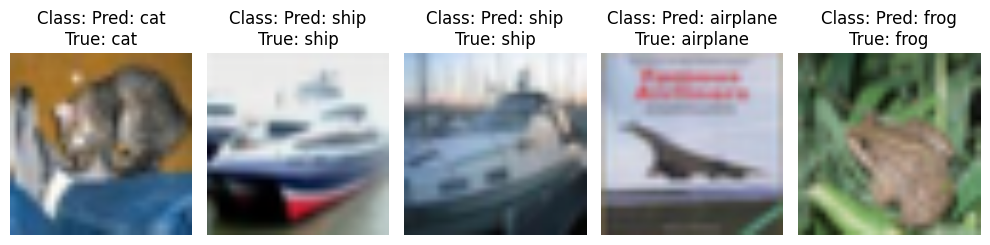


Model architecture:
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): 

In [37]:
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

def show_images(images, labels):
    plt.figure(figsize=(10, 4))
    for i in range(5):
        plt.subplot(1, 5, i+1)
        img = images[i].numpy().transpose((1, 2, 0))
        mean = np.array([0.4914, 0.4822, 0.4465])
        std = np.array([0.2023, 0.1994, 0.2010])
        img = std * img + mean
        img = np.clip(img, 0, 1)
        plt.imshow(img)
        plt.title(f'Class: {labels[i]}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def main():
    # Device configuration
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # Define transforms
    transform = transforms.Compose([
        transforms.Resize(224),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    ])

    # Load CIFAR10 dataset
    train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                                 download=True, transform=transform)
    test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                                download=True, transform=transform)

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    # Show some training images
    images, labels = next(iter(train_loader))
    class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                   'dog', 'frog', 'horse', 'ship', 'truck']
    show_images(images, [class_names[label] for label in labels[:5]])

    # Load pretrained ResNet18
    model = resnet18(weights=ResNet18_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, 10)  # CIFAR-10 has 10 classes
    model = model.to(device)

    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Training loop
    print("Training started...")
    num_epochs = 5
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            if (i + 1) % 100 == 0:
                print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{len(train_loader)}], '
                      f'Loss: {running_loss/100:.4f}')
                running_loss = 0.0

    # Test the model
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        print(f'Accuracy on test images: {100 * correct / total:.2f}%')

    # Show some predictions
    model.eval()
    images, labels = next(iter(test_loader))
    outputs = model(images.to(device))
    _, predicted = torch.max(outputs, 1)
    show_images(images, [f'Pred: {class_names[pred]}\nTrue: {class_names[label]}'
                         for pred, label in zip(predicted[:5].cpu(), labels[:5])])

    # Inspect model architecture
    print("\nModel architecture:")
    print(model)

    print("\nNamed parameters:")
    for name, param in model.named_parameters():
        print(f"Layer: {name}, Size: {param.size()}")

    print(f"\nFinal layer input features: {model.fc.in_features}")
    print(f"Final layer output features: {model.fc.out_features}")

    # Summary
    try:
        from torchsummary import summary
        print("\nTorchsummary:")
        summary(model, (3, 224, 224))
    except ImportError:
        print("torchsummary is not installed. Run `pip install torchsummary` to use model summary.")


if __name__ == '__main__':
    main()


In [ ]:
доступних (без пояснень архітектури)

Using device: cpu


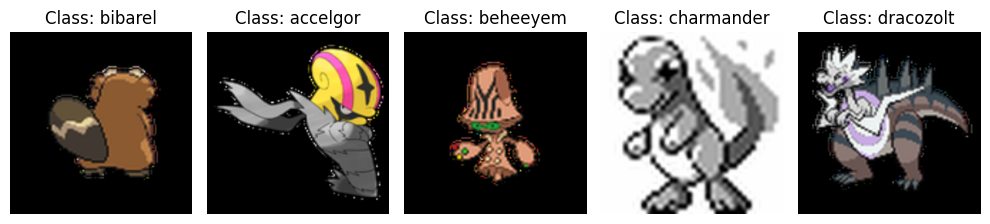

Training started...
Epoch [1/5], Step [100/159], Loss: 4.4150
Epoch [2/5], Step [100/159], Loss: 0.8253
Epoch [3/5], Step [100/159], Loss: 0.1709
Epoch [4/5], Step [100/159], Loss: 0.0682
Epoch [5/5], Step [100/159], Loss: 0.0265
Accuracy on test images: 88.91%


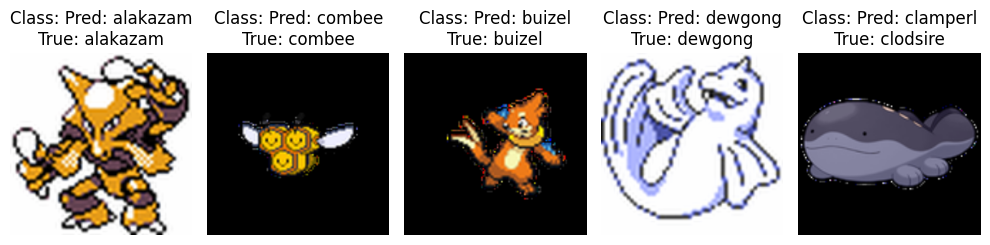

In [33]:
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
import os

def show_images(images, labels):
    plt.figure(figsize=(10, 4))
    for i in range(5):
        plt.subplot(1, 5, i+1)
        img = images[i].numpy().transpose((1, 2, 0))
        mean = np.array([0.4914, 0.4822, 0.4465])
        std = np.array([0.2023, 0.1994, 0.2010])
        img = std * img + mean
        img = np.clip(img, 0, 1)
        plt.imshow(img)
        plt.title(f'Class: {labels[i]}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def main():
    # Device configuration
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # Define transforms
    transform = transforms.Compose([
        transforms.Resize(224),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    ])

    # Шлях до вашого датасету
    dataset_root = './variant-1/variant-1'

    # Повний набір даних
    full_dataset = ImageFolder(root=dataset_root, transform=transform)

    # Розділення на train/test
    train_size = int(0.8 * len(full_dataset))
    test_size = len(full_dataset) - train_size
    train_dataset, test_dataset = torch.utils.data.random_split(full_dataset, [train_size, test_size])

    # Завантажувачі
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    # Отримання імен класів
    class_names = full_dataset.classes
    num_classes = len(class_names)

    images, labels = next(iter(train_loader))
    show_images(images, [train_dataset.dataset.classes[label] for label in labels[:5]])

    # Load pretrained ResNet18
    model = resnet18(weights=ResNet18_Weights.DEFAULT)
    # Replace final layer
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    model = model.to(device)

    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Training loop
    print("Training started...")
    num_epochs = 5
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            if (i + 1) % 100 == 0:
                print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{len(train_loader)}], '
                      f'Loss: {running_loss/100:.4f}')
                running_loss = 0.0

    # Test the model
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        print(f'Accuracy on test images: {100 * correct / total:.2f}%')

    # Show some predictions
    model.eval()
    images, labels = next(iter(test_loader))
    outputs = model(images.to(device))
    _, predicted = torch.max(outputs, 1)
    show_images(images, [f'Pred: {class_names[pred]}\nTrue: {class_names[label]}'
                        for pred, label in zip(predicted[:5].cpu(), labels[:5])])

if __name__ == '__main__':
    main()

In [ ]:
змінениа архітектура


In [14]:
def visualize_images(dataloader, class_names=None, num_images=5):
    images, labels = next(iter(dataloader))
    plt.figure(figsize=(15, 3))
    for i in range(num_images):
        img = images[i].numpy().transpose((1, 2, 0))
        img = np.clip(img * 0.5 + 0.5, 0, 1)
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        if class_names:
            plt.title(f'Class: {class_names[labels[i]]}')
        else:
            plt.title(f'Label: {labels[i].item()}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def visualize_predictions(model, dataloader, device, class_names=None, num_images=5):
    model.eval()
    images, labels = next(iter(dataloader))
    with torch.no_grad():
        outputs = model(images.to(device))
        _, predicted = torch.max(outputs, 1)

    plt.figure(figsize=(15, 3))
    for i in range(num_images):
        img = images[i].numpy().transpose((1, 2, 0))
        img = np.clip(img * 0.5 + 0.5, 0, 1)
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        if class_names:
            true_label = class_names[labels[i]]
            pred_label = class_names[predicted[i]]
            color = 'green' if labels[i] == predicted[i] else 'red'
            plt.title(f'True: {true_label}\nPred: {pred_label}', color=color)
        else:
            color = 'green' if labels[i] == predicted[i] else 'red'
            plt.title(f'True: {labels[i]}\nPred: {predicted[i]}', color=color)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

In [20]:
class OptimizedCNN(nn.Module):  #BatchNorm + Dropout
    def __init__(self, num_classes):
        super(OptimizedCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(64 * 28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x


In [24]:
def train_model(model, train_loader, criterion, optimizer, device, epochs=5):
    model.train()
    train_losses = []
    train_accs = []

    for epoch in range(epochs):
        total_loss = 0
        correct = 0
        total = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        epoch_loss = total_loss/len(train_loader)
        epoch_acc = correct/total
        train_losses.append(epoch_loss)
        train_accs.append(epoch_acc)
        print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}")

    return train_losses, train_accs

def evaluate_model(model, test_loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    accuracy = correct / total
    print(f'Test Accuracy: {accuracy:.4f}')
    return accuracy

Sample training images:


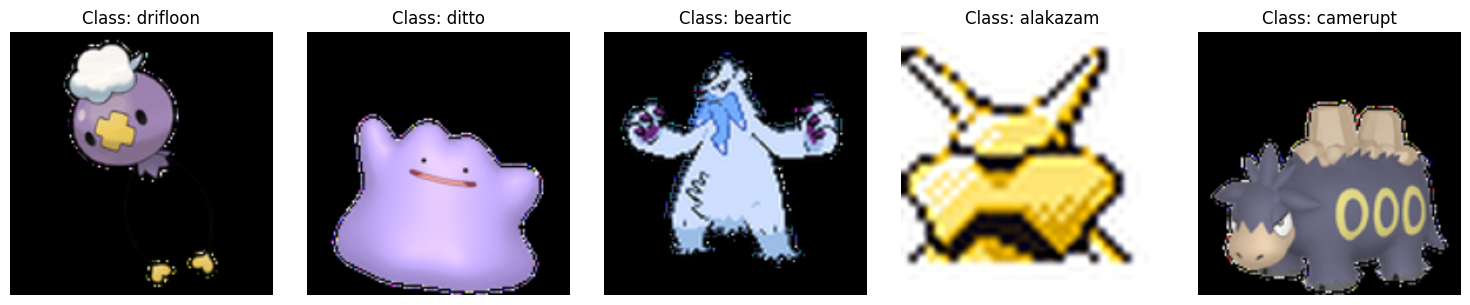


Training model...
Epoch 1/5, Loss: 5.6614, Accuracy: 0.0071
Epoch 2/5, Loss: 5.3540, Accuracy: 0.0130
Epoch 3/5, Loss: 5.2565, Accuracy: 0.0116
Epoch 4/5, Loss: 5.2224, Accuracy: 0.0100
Epoch 5/5, Loss: 5.1695, Accuracy: 0.0108

Evaluating model...
Test Accuracy: 0.0102

Model predictions on test set:


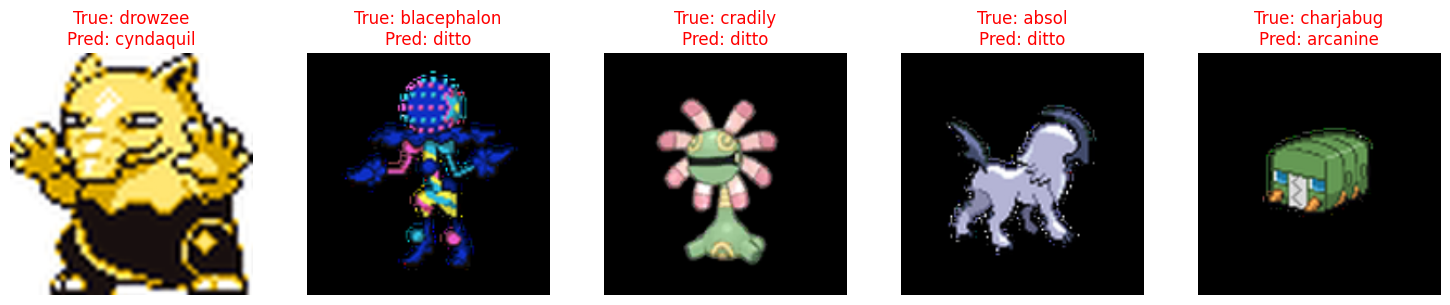

Model (loaded from checkpoint) predictions:


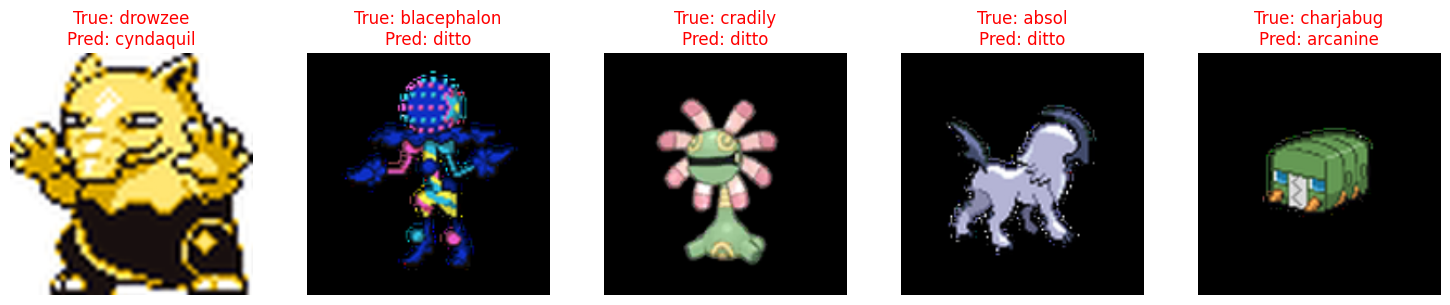

In [25]:
def main():
    # Set device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Define transforms
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    # Load dataset
    data_dir = "./variant-1/variant-1" # Provide your dataset directory
    train_dir = os.path.join(data_dir, "train")
    test_dir = os.path.join(data_dir, "test")

    if os.path.exists(train_dir) and os.path.exists(test_dir):
        train_dataset = ImageFolder(root=train_dir, transform=transform)
        test_dataset = ImageFolder(root=test_dir, transform=transform)
        class_names = train_dataset.classes
    else:
        dataset = ImageFolder(root=data_dir, transform=transform)
        class_names = dataset.classes
        indices = list(range(len(dataset)))
        train_indices, test_indices = train_test_split(indices, test_size=0.2, random_state=42)
        train_dataset = Subset(dataset, train_indices)
        test_dataset = Subset(dataset, test_indices)

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    # Visualize training images
    print("Sample training images:")
    visualize_images(train_loader, class_names)

    # Initialize model
    num_classes = len(class_names)
    model = OptimizedCNN(num_classes=num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Train model
    print("\nTraining model...")
    train_losses, train_accs = train_model(model, train_loader, criterion, optimizer, device, epochs=5)

    # Evaluate model
    print("\nEvaluating model...")
    test_accuracy = evaluate_model(model, test_loader, device)

    # Visualize predictions
    print("\nModel predictions on test set:")
    visualize_predictions(model, test_loader, device, class_names)

    # Save model
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_losses': train_losses,
        'train_accs': train_accs,
        'test_accuracy': test_accuracy,
        'class_names': class_names
    }, "model_checkpoint.pth")

    # Check that model is loaded correctly after saving
    load_and_visualize("model_checkpoint.pth", test_loader, device)

def load_and_visualize(checkpoint_path, test_loader, device):
    # Load checkpoint
    checkpoint = torch.load(checkpoint_path)
    num_classes = len(checkpoint['class_names'])

    # Initialize and load model
    model = OptimizedCNN(num_classes=num_classes).to(device)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval()

    # Visualize predictions
    print("Model (loaded from checkpoint) predictions:")
    visualize_predictions(model, test_loader, device, checkpoint['class_names'])

    return model

if __name__ == '__main__':
    main()

In [28]:
class SimpleEfficientCNN(nn.Module):   # Dropout
    def __init__(self, num_classes):
        super(SimpleEfficientCNN, self).__init__()
        self.conv_block = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),  # вхід: 3 → 32
            nn.ReLU(),
            nn.MaxPool2d(2, 2),                         # 224 → 112

            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # 32 → 64
            nn.ReLU(),
            nn.MaxPool2d(2, 2),                         # 112 → 56
        )

        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 56 * 56, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.conv_block(x)
        x = self.fc(x)
        return x


Sample training images:


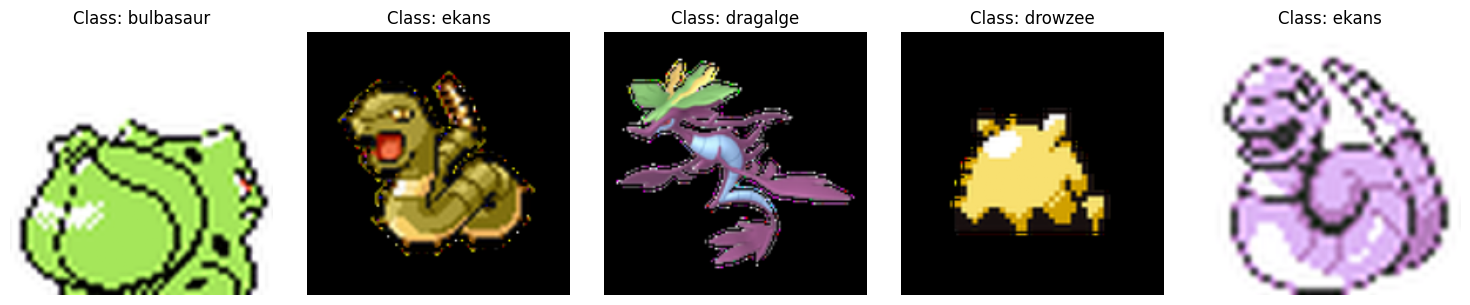


Training model...
Epoch 1/5, Loss: 5.4877, Accuracy: 0.0146
Epoch 2/5, Loss: 4.1744, Accuracy: 0.1538
Epoch 3/5, Loss: 2.4077, Accuracy: 0.4519
Epoch 4/5, Loss: 1.4443, Accuracy: 0.6445
Epoch 5/5, Loss: 0.9734, Accuracy: 0.7448

Evaluating model...
Test Accuracy: 0.7183

Model predictions on test set:


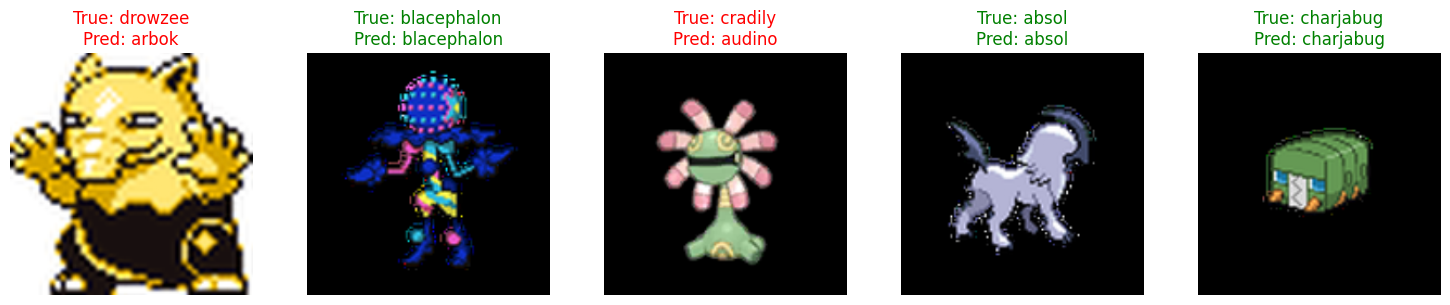

Model (loaded from checkpoint) predictions:


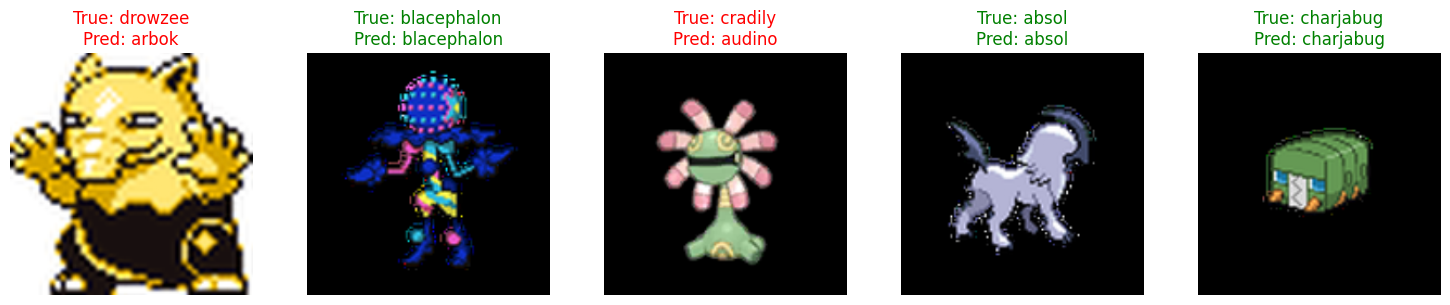

In [29]:
def main():
    # Set device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Define transforms
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    # Load dataset
    data_dir = "./variant-1/variant-1" # Provide your dataset directory
    train_dir = os.path.join(data_dir, "train")
    test_dir = os.path.join(data_dir, "test")

    if os.path.exists(train_dir) and os.path.exists(test_dir):
        train_dataset = ImageFolder(root=train_dir, transform=transform)
        test_dataset = ImageFolder(root=test_dir, transform=transform)
        class_names = train_dataset.classes
    else:
        dataset = ImageFolder(root=data_dir, transform=transform)
        class_names = dataset.classes
        indices = list(range(len(dataset)))
        train_indices, test_indices = train_test_split(indices, test_size=0.2, random_state=42)
        train_dataset = Subset(dataset, train_indices)
        test_dataset = Subset(dataset, test_indices)

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    # Visualize training images
    print("Sample training images:")
    visualize_images(train_loader, class_names)

    # Initialize model
    num_classes = len(class_names)
    model = SimpleEfficientCNN(num_classes=num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Train model
    print("\nTraining model...")
    train_losses, train_accs = train_model(model, train_loader, criterion, optimizer, device, epochs=5)

    # Evaluate model
    print("\nEvaluating model...")
    test_accuracy = evaluate_model(model, test_loader, device)

    # Visualize predictions
    print("\nModel predictions on test set:")
    visualize_predictions(model, test_loader, device, class_names)

    # Save model
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_losses': train_losses,
        'train_accs': train_accs,
        'test_accuracy': test_accuracy,
        'class_names': class_names
    }, "model_checkpoint.pth")

    # Check that model is loaded correctly after saving
    load_and_visualize("model_checkpoint.pth", test_loader, device)

def load_and_visualize(checkpoint_path, test_loader, device):
    # Load checkpoint
    checkpoint = torch.load(checkpoint_path)
    num_classes = len(checkpoint['class_names'])

    # Initialize and load model
    model = SimpleEfficientCNN(num_classes=num_classes).to(device)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval()

    # Visualize predictions
    print("Model (loaded from checkpoint) predictions:")
    visualize_predictions(model, test_loader, device, checkpoint['class_names'])

    return model

if __name__ == '__main__':
    main()

In [ ]:
доступних виправлено (з поясненням архітектури)

Using device: cpu


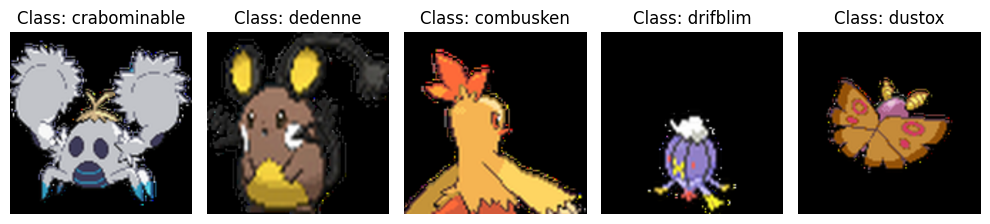

Training started...
Epoch [1/5], Step [100/159], Loss: 4.2465
Epoch [2/5], Step [100/159], Loss: 0.7895
Epoch [3/5], Step [100/159], Loss: 0.1717
Epoch [4/5], Step [100/159], Loss: 0.0583
Epoch [5/5], Step [100/159], Loss: 0.0232
Accuracy on test images: 97.64%


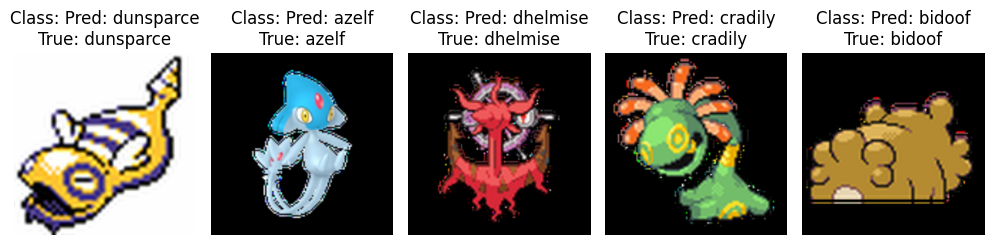

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [36]:
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
import os
from torchsummary import torchsummary

def show_images(images, labels):
    plt.figure(figsize=(10, 4))
    for i in range(5):
        plt.subplot(1, 5, i+1)
        img = images[i].numpy().transpose((1, 2, 0))
        mean = np.array([0.4914, 0.4822, 0.4465])
        std = np.array([0.2023, 0.1994, 0.2010])
        img = std * img + mean
        img = np.clip(img, 0, 1)
        plt.imshow(img)
        plt.title(f'Class: {labels[i]}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def main():
    # Device configuration
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # Define transforms
    transform = transforms.Compose([
        transforms.Resize(224),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    ])

    # Шлях до вашого датасету
    dataset_root = './variant-1/variant-1'

    # Повний набір даних
    full_dataset = ImageFolder(root=dataset_root, transform=transform)

    # Розділення на train/test
    train_size = int(0.8 * len(full_dataset))
    test_size = len(full_dataset) - train_size
    train_dataset, test_dataset = torch.utils.data.random_split(full_dataset, [train_size, test_size])

    # Завантажувачі
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    # Отримання імен класів
    class_names = full_dataset.classes
    num_classes = len(class_names)

    images, labels = next(iter(train_loader))
    show_images(images, [train_dataset.dataset.classes[label] for label in labels[:5]])

    # Load pretrained ResNet18
    model = resnet18(weights=ResNet18_Weights.DEFAULT)
    # Replace final layer
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    model = model.to(device)

    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Training loop
    print("Training started...")
    num_epochs = 5
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            if (i + 1) % 100 == 0:
                print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{len(train_loader)}], '
                      f'Loss: {running_loss/100:.4f}')
                running_loss = 0.0

    # Test the model
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        print(f'Accuracy on test images: {100 * correct / total:.2f}%')

    # Show some predictions
    model.eval()
    images, labels = next(iter(test_loader))
    outputs = model(images.to(device))
    _, predicted = torch.max(outputs, 1)
    show_images(images, [f'Pred: {class_names[pred]}\nTrue: {class_names[label]}'
                        for pred, label in zip(predicted[:5].cpu(), labels[:5])])

    # Inspect model architecture
    print(model)  # Prints complete model architecture

    # To find the final layer's input features:
    for name, param in model.named_parameters():
        print(f"Layer: {name}, Size: {param.size()}")

    # Example of checking specific layer:
    print(f"Final layer input features: {model.fc.in_features}")  # For ResNet
    print(f"Final layer output features: {model.fc.out_features}")

    # More detailed inspection:
    torchsummary.summary(model, (3, 224, 224))  # Prints detailed layer info

if __name__ == '__main__':
    main()


ResNet18 має значно кращі результати (97.64%) завдяки більш складній архітектурі, що дозволяє моделі ефективніше навчатися та уникати проблеми перенавчання. Якщо точність є важливим критерієм, то ResNet18 виглядає кращим вибором.

CNN (accuracity = 79.31%) може бути корисним для менш складних задач, де час навчання є критичним фактором або коли потрібно уникати використання складних моделей.

Покращені моделі CNN мають таку точність: OptimizedCNN 1.02% і SimpleEfficientCNN 71.83%